In [1]:
experiement_pth = '../test_results/evals'
analysis_pth = '../test_results/plots/'
print('Hello World')

Hello World


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

def compare_loss_curves(models, labels, losses=['total loss'], path="", yscales=['linear'], interval=10):

    ### Check if save directory exists
    os.makedirs(os.path.join(experiement_pth, path), exist_ok=True)

    
    # Plot each loss
    for i, loss in enumerate(losses):
        plt.close()
        plt.title(loss)
        for j, mdl in enumerate(models):
            df = pd.read_csv(os.path.join(mdl, 'losses.csv'))
            plt.plot(df[loss][::interval], label=labels[j])
        plt.yscale(yscales[i])
        plt.legend()
        plt.savefig(os.path.join(experiement_pth, path, loss + '.png'))
        plt.show()

def get_success_rate_and_steps(path):
    df = pd.read_csv(path)

    successes = df['evaluation/success'].to_list()
    successes = [n.strip("[]").split(", ") for n in successes]
    successes = [[1 if mm == 'True' else 0 for mm in n] for n in successes]
    # successes = np.asarray(successes)

    eps = len(successes)
    ## reduce the succeess to 1 if any of the episode is success
    success_eps = []
    for i in range(eps):
        success_eps.append(np.any(successes[i]))

    # get the success rate
    rate = np.sum(success_eps) / len(success_eps)

    ## get steps-to-success if an episode is success
    steps_to_success = []
    for i in range(eps):
        if success_eps[i]:
            steps_to_success.append(np.argmax(successes[i])+1)
        else:
            steps_to_success.append(30)
    
    # np.argmax(successes, axis=1)

    # filter out the episode that is not success
    # steps_to_success = np.asarray(steps_to_success)
    # steps_to_success = steps_to_success[success_eps]

    return rate, steps_to_success, eps

# def get_metrics(path, step=30, success_criteria=0):
#     df = pd.read_csv(path)

#     if success_criteria == 0:
#         success_fn = lambda x, y: x > 0.90 and y > 0.80
#     elif success_criteria == 1:
#         success_fn = lambda x, y: x > 0.90


#     NC = df['evaluation/normalised_coverage'].to_list()
#     NC = [n.strip("[]").split(", ") for n in NC]
#     NC = [[float(mm) for mm in n] for n in NC]
#     NC = np.asarray(NC)
#     ret_NC = []
#     NI = df['evaluation/normalised_improvement'].to_list()
#     NI = [n.strip("[]").split(", ") for n in NI]
#     NI = [[float(mm) for mm in n] for n in NI]
#     ret_NI = []

#     IoU = df['evaluation/max_IoU'].to_list()
#     IoU = [n.strip("[]").split(", ") for n in IoU]
#     IoU = [[float(mm) for mm in n] for n in IoU]
#     ret_IoU = []

#     HD = df['evaluation/normalised_hausdorff_distance'].to_list()
#     HD = [n.strip("[]").split(", ") for n in HD]
#     HD = [[float(mm) for mm in n] for n in HD]
#     ret_HD = []
#     step2success = []

#     for i in range(len(NC)):
#         ret_NC.append(NC[i][-1])
#         ret_NI.append(NI[i][-1])
#         ret_IoU.append(IoU[i][-1])
#         ret_HD.append(HD[i][-1])
#         step2success.append(len(NC[i])-1)
#         for j in range(len(NC[i])):
#             if success_fn(NC[i][j], IoU[i][j]):
#                 ret_NC[-1] = NC[i][j]
#                 ret_NI[-1] = NI[i][j]
#                 ret_IoU[-1] = IoU[i][j]
#                 ret_HD[-1] = HD[i][j]
#                 step2success[-1] = j
#                 break
    
#     total_eps = len(NC)
#     success_eps = 0
#     # get SR, for each episode, NC should be larger than 0.99 and IoU should be larger than 0.85

#     for i in range(total_eps):
#         if success_fn(ret_NC[i], ret_IoU[i]):
#             success_eps += 1



#     return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success

def get_metrics(path, step=30, success_criteria=0):
    df = pd.read_csv(path)

    if success_criteria == 0:
        success_fn = lambda x, y: x > 0.90 and y > 0.80
    elif success_criteria == 1:
        success_fn = lambda x, y: x > 0.90

    NC = df['evaluation/normalised_coverage'].to_list()
    NC = [n.strip("[]").split(", ") for n in NC]
    NC = [[float(mm) for mm in n] for n in NC]
    NC = np.asarray(NC)
    ret_NC = []
    NI = df['evaluation/normalised_improvement'].to_list()
    NI = [n.strip("[]").split(", ") for n in NI]
    NI = [[float(mm) for mm in n] for n in NI]
    ret_NI = []

    IoU = df['evaluation/max_IoU'].to_list()
    IoU = [n.strip("[]").split(", ") for n in IoU]
    IoU = [[float(mm) for mm in n] for n in IoU]
    ret_IoU = []

    HD = df['evaluation/normalised_hausdorff_distance'].to_list()
    HD = [n.strip("[]").split(", ") for n in HD]
    HD = [[float(mm) for mm in n] for n in HD]
    ret_HD = []
    step2success = []

    for i in range(len(NC)):
        # Only consider up to `step` steps for each episode
        max_idx = min(step, len(NC[i]))
        # Default to the last available step within the window
        ret_NC.append(NC[i][max_idx-1])
        ret_NI.append(NI[i][max_idx-1])
        ret_IoU.append(IoU[i][max_idx-1])
        ret_HD.append(HD[i][max_idx-1])
        step2success.append(max_idx-1)
        for j in range(max_idx):
            if success_fn(NC[i][j], IoU[i][j]):
                ret_NC[-1] = NC[i][j]
                ret_NI[-1] = NI[i][j]
                ret_IoU[-1] = IoU[i][j]
                ret_HD[-1] = HD[i][j]
                step2success[-1] = j
                break

    total_eps = len(NC)
    success_eps = 0

    for i in range(total_eps):
        if success_fn(ret_NC[i], ret_IoU[i]):
            success_eps += 1

    return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success


In [ ]:
agents = [
    'rssm',
    'gc_rssm',
    'human-pixel-pick-and-place-1',
    'diffusion_policy',
    'cloth-funnel',
    'transporter'
]

objects = [
    'longsleeve',
    'smallLongsleeve',
    'pants',
    'smallPants',
    'skirt',
    'smallSkirt',
    'dress',
    'smallDress',
    'mono-square-fabric'
]

step=31
arenas = []
arena_label = []

### Collect all the config for each arena, agent
configs = {ag: []  for ag in agents}
for ag in agents:
    lafruita_path = os.path.join(experiement_pth, ag)
    if os.path.exists(lafruita_path):
        for cf in os.listdir(lafruita_path):
            path_to_check = os.path.join(lafruita_path, cf)
            configs[ag].append(cf)
data = {
    'task': [],
    'agent': [],
    'config': [],
    # 'domain': [],
    'object': [],
    # 'success rate': [],
    # 'steps to success': [],
    # 'steps to success std': [],
    'ni': [], # largest particle distance
    'nc': [],
    'ni std': [],
    'nc std': [],
    'IoU': [],
    'HD': [],
    'IoU std': [],
    'HD std': [],
    'steps': [],
    'steps std': [],
    # 'max key dist': [],
    # 'mean key dist': [],
    'episodes': [],
    'success_eps': [],
    'path': [],
    'checkpoint': []
}
print(arenas)
### For all configs, get the success rate and steps to success

for ag in agents:
    #print('\n', " "*4, 'Agent:', agent_lable[ar][agents[ar].index(ag)])
    for cf in configs[ag]:
        for ob in objects:
            path = os.path.join(experiement_pth, ag, cf, ob)
            if not os.path.isdir(path):
                continue

            for f in os.listdir(path):
                #print(f)
                if 'manupilation' not in f:
                    continue
            
                path_to_check = os.path.join(path, f, 'performance.csv') 
                
                #print(path_to_check)
                
                if os.path.exists(path_to_check):

                    checkpoint_parsing = f.split('.')[0].split('_')
                    #print(checkpoint_parsing)
                    if len(checkpoint_parsing) == 2:
                        if checkpoint_parsing[1] == '':
                            continue
                        #print(checkpoint_parsing[1])
                        data['checkpoint'].append(str(checkpoint_parsing[1]))
                    else: 
                        data['checkpoint'].append('-1')


                
                    data['path'].append(path)
                    #print(path)

                   # domain = path.split('|')[1].split(':')[1].split('-')[0]
                    #data['domain'].append(domain)
                    #obj = path.split('|')[1].split(':')[1].split('-')[-1].split(',')[0]
                    data['object'].append(ob)
                    
                    data['task'].append('flattening')
                    

                    success_criteria = 0
                    if ob == 'fabric':
                        success_criteria = 1
                    nc, ni, IoU, hd, eps, success_eps, steps = get_metrics(path_to_check, step=step, success_criteria=success_criteria)
                    data['episodes'].append(eps)
                    data['nc'].append(np.mean(nc))
                    data['ni'].append(np.mean(ni))
                    data['nc std'].append(np.std(nc))
                    data['ni std'].append(np.std(ni))
                    data['success_eps'].append(success_eps)
                    data['steps'].append(np.mean(steps))
                    data['steps std'].append(np.std(steps))

                    data['IoU'].append(np.mean(IoU))
                    data['HD'].append(np.mean(hd))
                    data['IoU std'].append(np.std(IoU))
                    data['HD std'].append(np.std(hd))

                    # max_key_dist, mean_key_dist = get_key_dist(path_to_check, step=step)
                    # data['max key dist'].append(np.mean(max_key_dist))
                    # data['mean key dist'].append(np.mean(mean_key_dist))

                    data['agent'].append(ag)

                    # replace '_' with ' '
                    cf_name = cf.replace('_', ' ')
                    data['config'].append(cf_name)
                # data['success rate'].append(rate)
                # data['steps to success'].append(np.mean(steps_to_success))
                # data['steps to success std'].append(np.std(steps_to_success))




## Plot the success rate and steps to success
backup_df = pd.DataFrame(data)
df = pd.DataFrame(data)

display(df)



SyntaxError: invalid syntax (715844630.py, line 22)

In [ ]:

def combine_mean_std(row, metric, scale=100):
    mean = row[metric]*scale
    std = row[f"{metric} std"]*scale
    return f"{mean:.1f} $\pm$ {std:.1f}"

In [ ]:
data_df_ = df[df['config'].str.contains('recon-RGB2M')]
display(data_df_)

,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
76,flattening,gc_rssm,recon-RGB2M-1r1,longsleeve,0.857567,0.934856,0.121087,0.062535,0.759579,0.055299,0.095545,0.022141,21.566667,9.482206,30,19,../test_results/evals/gc_rssm/recon-RGB2M-1r1/...,46000
77,flattening,gc_rssm,recon-RGB2M-1r1,pants,0.900810,0.956365,0.077651,0.037067,0.842282,0.024536,0.031193,0.006233,15.333333,8.279828,6,6,../test_results/evals/gc_rssm/recon-RGB2M-1r1/...,49000
118,flattening,gc_rssm,recon-RGB2M,longsleeve,0.871998,0.941674,0.115522,0.061287,0.795413,0.045982,0.072544,0.018639,19.033333,9.271761,30,23,../test_results/evals/gc_rssm/recon-RGB2M/long...,50000
119,flattening,gc_rssm,recon-RGB2M,longsleeve,0.826644,0.927040,0.170699,0.075382,0.782946,0.050109,0.089526,0.019154,20.733333,9.430211,30,21,../test_results/evals/gc_rssm/recon-RGB2M/long...,96000
120,flattening,gc_rssm,recon-RGB2M,pants,0.900993,0.956897,0.072941,0.034176,0.857539,0.024889,0.023516,0.004038,14.500000,9.305017,6,6,../test_results/evals/gc_rssm/recon-RGB2M/pants,100000
121,flattening,gc_rssm,recon-RGB2M,pants,0.884678,0.953708,0.107619,0.045747,0.780970,0.036434,0.128720,0.019428,15.900000,9.399823,30,25,../test_results/evals/gc_rssm/recon-RGB2M/pants,50000
122,flattening,gc_rssm,recon-RGB2M,skirt,0.813461,0.919334,0.106171,0.051515,0.848047,0.036922,0.039252,0.011714,10.800000,7.968270,30,27,../test_results/evals/gc_rssm/recon-RGB2M/skirt,50000
123,flattening,gc_rssm,recon-RGB2M,dress,0.827759,0.930559,0.099635,0.040025,0.835753,0.035845,0.043006,0.011673,10.833333,6.918976,30,28,../test_results/evals/gc_rssm/recon-RGB2M/dress,50000


In [ ]:
data_df_ = df[df['object'] == 'longsleeve']
agent_tuples = [
    ('human-pixel-pick-and-place-1', 'default', '-1', 'Human'),
    ('transporter', 'JA-TN-depth-50-human', '50001', 'JA-TN'),
    ('diffusion_policy', 'masked-depth-human-50', '49999', 'Diffusion Policy'),
    ('rssm', 'all-garment', '50000', 'PlaNet-ClothPick\n(All Garment)'), # config all-garment is training.
    ('cloth-funnel', 'place-only', '-1', 'ClothFunnels'),
    ('gc_rssm', 'task-focused', '50000', 'LaGarNet\n(Task Focused)'),
    ('gc_rssm', 'recon-RGB2M', '50000', 'LaGarNet\n(All Garments)'),
    ('rssm', 'task-focused', '50000', 'PlaNet-ClothPick\n(Task Focused)'), # config task-focused is training.
]


## get the row that the agent keys are in the agent_configs, and its config and checkpoint are in its corresponding values
## using lamda function
def match_row(row, tuples):
    for agent, config, checkpoint, label in tuples:
        if (
            row['agent'] == agent and
            row['config'] == config and
            (row['checkpoint'] == checkpoint or checkpoint == -1)
        ):
            return label
    return None

# Apply to data_df_
data_df = data_df_.copy()
data_df['label'] = data_df.apply(lambda row: match_row(row, agent_tuples), axis=1)
data_df = data_df[data_df['label'].notnull()]
data_df['agent'] = data_df['label']
# List of metrics to combine
metrics = ['ni', 'nc', 'IoU', 'steps']
labels = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$']#, 'S2F $\\downarrow$']

# Apply the combination for each metric
for m, l in zip(metrics, labels):
    if m == 'steps':
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m, scale=1), axis=1)
    else:
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m), axis=1)

data_df['SR $\\uparrow$'] = data_df['success_eps'].apply(lambda x: f"{x}/30")

display(data_df)
## create a latex table where columns are the agents, and rows are the metrics

def generate_latex_table(data_df):
    agents = ['ClothFunnels', 'JA-TN', 'Diffusion Policy', \
              'PlaNet-ClothPick\n(Task Focused)', 'PlaNet-ClothPick\n(All Garment)', \
            'LaGarNet\n(Task Focused)', 'LaGarNet\n(All Garments)', 'Human']
    metrics = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$', 'SR $\\uparrow$']

    latex_table = "\\begin{table}[]\n\\begin{tabular}{l|cccp{2.1cm}p{2.1cm}p{1.8cm}p{1.8cm}||c}\n"
    for agent in agents:
        latex_table += f" & {agent}"
    latex_table += "\\\\\n"
    latex_table += "\\hline\n"
    for metric in metrics:
        latex_table += metric + '&'
        for agent in agents:
           
            metrics_value = data_df[data_df['agent'] == agent][metric]
            #print(agent, metrics)
            metrics_value = metrics_value.values[0]
            latex_table += f"{metrics_value} & "
        latex_table = latex_table[:-2] + "\\\\\n"
    latex_table += "\\end{tabular}\n\\end{table}"
    return latex_table

latex_table = generate_latex_table(data_df)
print(latex_table)

,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,...,steps std,episodes,success_eps,path,checkpoint,label,NI $\uparrow$,NC $\uparrow$,Max IoU $\uparrow$,SR $\uparrow$
4,flattening,PlaNet-ClothPick\n(Task Focused),task-focused,longsleeve,0.498364,0.771923,0.221862,0.097026,0.623672,0.088788,...,7.044304,30,3,../test_results/evals/rssm/task-focused/longsl...,50000,PlaNet-ClothPick\n(Task Focused),49.8 $\pm$ 22.2,77.2 $\pm$ 9.7,62.4 $\pm$ 9.1,3/30
5,flattening,PlaNet-ClothPick\n(All Garment),all-garment,longsleeve,0.534422,0.784688,0.179895,0.087624,0.618513,0.091974,...,2.259794,30,2,../test_results/evals/rssm/all-garment/longsleeve,50000,PlaNet-ClothPick\n(All Garment),53.4 $\pm$ 18.0,78.5 $\pm$ 8.8,61.9 $\pm$ 8.1,2/30
62,flattening,LaGarNet\n(Task Focused),task-focused,longsleeve,0.788044,0.898564,0.171721,0.088008,0.725150,0.061635,...,9.812917,30,17,../test_results/evals/gc_rssm/task-focused/lon...,50000,LaGarNet\n(Task Focused),78.8 $\pm$ 17.2,89.9 $\pm$ 8.8,72.5 $\pm$ 12.9,17/30
118,flattening,LaGarNet\n(All Garments),recon-RGB2M,longsleeve,0.871998,0.941674,0.115522,0.061287,0.795413,0.045982,...,9.271761,30,23,../test_results/evals/gc_rssm/recon-RGB2M/long...,50000,LaGarNet\n(All Garments),87.2 $\pm$ 11.6,94.2 $\pm$ 6.1,79.5 $\pm$ 7.3,23/30
132,flattening,Human,default,longsleeve,0.913370,0.964982,0.086964,0.033188,0.818775,0.035883,...,8.137704,30,29,../test_results/evals/human-pixel-pick-and-pla...,-1,Human,91.3 $\pm$ 8.7,96.5 $\pm$ 3.3,81.9 $\pm$ 3.2,29/30
133,flattening,Diffusion Policy,masked-depth-human-50,longsleeve,0.787438,0.899349,0.177557,0.086528,0.707047,0.062129,...,6.326312,30,11,../test_results/evals/diffusion_policy/masked-...,49999,Diffusion Policy,78.7 $\pm$ 17.8,89.9 $\pm$ 8.7,70.7 $\pm$ 10.9,11/30
134,flattening,ClothFunnels,place-only,longsleeve,0.546149,0.790867,0.219827,0.118845,0.559076,0.090166,...,0.718022,30,2,../test_results/evals/cloth-funnel/place-only/...,-1,ClothFunnels,54.6 $\pm$ 22.0,79.1 $\pm$ 11.9,55.9 $\pm$ 15.2,2/30
135,flattening,JA-TN,JA-TN-depth-50-human,longsleeve,0.422677,0.704962,0.325279,0.183584,0.571371,0.098871,...,4.962526,30,4,../test_results/evals/transporter/JA-TN-depth-...,50001,JA-TN,42.3 $\pm$ 32.5,70.5 $\pm$ 18.4,57.1 $\pm$ 14.2,4/30


\begin{table}[]
\begin{tabular}{l|cccp{2.1cm}p{2.1cm}p{1.8cm}p{1.8cm}||c}
 & ClothFunnels & JA-TN & Diffusion Policy & PlaNet-ClothPick
(Task Focused) & PlaNet-ClothPick
(All Garment) & LaGarNet
(Task Focused) & LaGarNet
(All Garments) & Human\\
\hline
NI $\uparrow$&54.6 $\pm$ 22.0 & 42.3 $\pm$ 32.5 & 78.7 $\pm$ 17.8 & 49.8 $\pm$ 22.2 & 53.4 $\pm$ 18.0 & 78.8 $\pm$ 17.2 & 87.2 $\pm$ 11.6 & 91.3 $\pm$ 8.7 \\
NC $\uparrow$&79.1 $\pm$ 11.9 & 70.5 $\pm$ 18.4 & 89.9 $\pm$ 8.7 & 77.2 $\pm$ 9.7 & 78.5 $\pm$ 8.8 & 89.9 $\pm$ 8.8 & 94.2 $\pm$ 6.1 & 96.5 $\pm$ 3.3 \\
Max IoU $\uparrow$&55.9 $\pm$ 15.2 & 57.1 $\pm$ 14.2 & 70.7 $\pm$ 10.9 & 62.4 $\pm$ 9.1 & 61.9 $\pm$ 8.1 & 72.5 $\pm$ 12.9 & 79.5 $\pm$ 7.3 & 81.9 $\pm$ 3.2 \\
SR $\uparrow$&2/30 & 4/30 & 11/30 & 3/30 & 2/30 & 17/30 & 23/30 & 29/30 \\
\end{tabular}
\end{table}


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
22,flattening,rssm,recon-RGB2RGB,longsleeve,0.825259,0.925468,0.191898,0.071165,0.726695,0.065114,0.101095,0.025932,24.100000,9.310746,30,13,../test_results/evals/rssm/recon-RGB2RGB/longs...,50000
23,flattening,rssm,recon-RGB2RGB,pants,0.878653,0.946218,0.118969,0.060456,0.727476,0.043467,0.131634,0.020588,20.933333,9.433746,30,17,../test_results/evals/rssm/recon-RGB2RGB/pants,50000
24,flattening,rssm,recon-RGB2RGB,skirt,0.764649,0.898900,0.176558,0.090370,0.831760,0.039482,0.066914,0.013290,13.666667,9.202657,30,24,../test_results/evals/rssm/recon-RGB2RGB/skirt,50000
25,flattening,rssm,recon-RGB2RGB,dress,0.778465,0.904936,0.161687,0.075665,0.816794,0.036999,0.061977,0.011336,13.200000,9.658847,30,26,../test_results/evals/rssm/recon-RGB2RGB/dress,50000
26,flattening,rssm,recon-GC-Input-Only-RGB2RGB,longsleeve,0.709633,0.860517,0.249207,0.117462,0.696361,0.067490,0.126901,0.029255,25.266667,7.797150,30,12,../test_results/evals/rssm/recon-GC-Input-Only...,50000
27,flattening,rssm,recon-GC-Input-Only-RGB2RGB,pants,0.879568,0.949606,0.095081,0.043504,0.746827,0.038936,0.125846,0.017255,19.600000,9.645724,30,20,../test_results/evals/rssm/recon-GC-Input-Only...,50000
28,flattening,rssm,recon-GC-Input-Only-RGB2RGB,skirt,0.803980,0.914283,0.137382,0.067646,0.841549,0.037228,0.050750,0.012334,13.666667,9.224364,30,26,../test_results/evals/rssm/recon-GC-Input-Only...,50000
29,flattening,rssm,recon-GC-Input-Only-RGB2RGB,dress,0.803967,0.921068,0.119687,0.046807,0.831945,0.035165,0.032691,0.009695,11.000000,8.148620,30,28,../test_results/evals/rssm/recon-GC-Input-Only...,50000
46,flattening,rssm,recon-GC-IO-RGB2RGB,longsleeve,0.672344,0.835245,0.221827,0.122524,0.665336,0.075651,0.134781,0.033099,25.966667,7.120315,30,8,../test_results/evals/rssm/recon-GC-IO-RGB2RGB...,50000
47,flattening,rssm,recon-GC-IO-RGB2RGB,pants,0.881077,0.951394,0.108122,0.047300,0.720618,0.042919,0.135199,0.019563,20.333333,10.047664,30,18,../test_results/evals/rssm/recon-GC-IO-RGB2RGB...,50000


[('rssm', 'recon-RGB2RGB'), ('rssm', 'recon-GC-Input-Only-RGB2RGB'), ('rssm', 'recon-GC-IO-RGB2RGB'), ('gc_rssm', 'recon-RGB2RGB')]


,label,nc,IoU,ni,episodes,success_eps,f1,sr
0,GC-RSSM,0.929611,0.790127,0.829272,120,89,85.421216,74.166667
1,RSSM,0.918880,0.775681,0.811756,120,80,84.123031,66.666667
2,"RSSM, GC-I",0.911369,0.779171,0.799287,120,86,84.010081,71.666667
3,"RSSM, GC-IO",0.905748,0.765357,0.783770,120,82,82.965558,68.333333


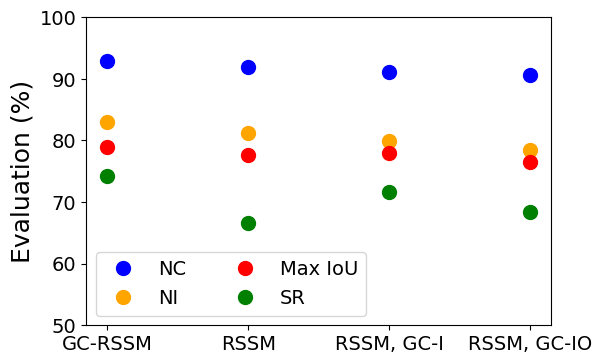

In [ ]:
recon_df = df[(df['config'].str.contains('recon'))]
recon_df = recon_df[~recon_df['config'].str.contains('RGB2M')]

display(recon_df)

agent_config2label = {
    ('rssm', 'recon-RGB2RGB'): 'RSSM',
    ('rssm', 'recon-GC-Input-Only-RGB2RGB'): 'RSSM, GC-I',
    ('rssm', 'recon-GC-IO-RGB2RGB'): 'RSSM, GC-IO',
    ('gc_rssm', 'recon-RGB2RGB'): 'GC-RSSM'
}


custom_order = list(agent_config2label.keys())

print(custom_order)

recon_df['agent_config'] = list(zip(recon_df['agent'], recon_df['config']))

# Map the tuple to the label
recon_df['label'] = recon_df['agent_config'].map(agent_config2label)

# Map each ('agent', 'config') pair to its position in the custom order
recon_df['sort_key'] = recon_df[['agent', 'config']].apply(tuple, axis=1).map({k: i for i, k in enumerate(custom_order)})

# Sort by the custom key
recon_df = recon_df.sort_values('sort_key').drop(columns=['sort_key'])

recon_df = recon_df.groupby('label').agg({
    'nc': 'mean',
    'IoU': 'mean',
    'ni': 'mean',
    'episodes': 'sum',
    'success_eps': 'sum'
}).reset_index()



## get the f1 score for each config using NC and IoU
recon_df['f1'] = 2*recon_df['nc']*recon_df['IoU']/(recon_df['nc'] + recon_df['IoU'])
recon_df['f1'] = recon_df['f1']*100
recon_df['sr'] = recon_df['success_eps']/recon_df['episodes'] * 100
# s
display(recon_df)

y_min = 50
y_max = 100


## show goal augmentation
goal_df = recon_df
## get rid of " Augmentation" in the config
# goal_df['config'] = goal_df['config'].str.replace(' Augmentation', '')
# plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
# plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')

plt.figure(figsize=(6, 4))  # Optional: make the figure larger

plt.ylabel('Evaluation (%)', fontsize=18)
plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC', markersize=10)
plt.plot(goal_df['label'], goal_df['ni']*100, color='orange', marker='o', linestyle='', label='NI', markersize=10)
plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU', markersize=10)
plt.plot(goal_df['label'], goal_df['sr'], color='green', marker='o', linestyle='', label='SR', markersize=10)

plt.ylim(y_min, y_max)
plt.legend(fontsize=14,ncol=2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
# plt.title('F1 Score for Reward Ablation', fontsize=20)
# plt.title('F1 Score for Goal Augmentation', fontsize=20)

plt.savefig(os.path.join(analysis_pth, 'goal-ablation.png'), bbox_inches='tight')
plt.show()


,task,agent,config,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
58,flattening,gc_rssm,cf-reward,longsleeve,0.003619,0.364895,0.018710,0.035676,0.353546,0.156945,0.031377,0.027010,30.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/longsl...,50000
59,flattening,gc_rssm,cf-reward,pants,0.036604,0.485748,0.071713,0.071349,0.441004,0.076377,0.057801,0.012580,30.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/pants,50000
60,flattening,gc_rssm,cf-reward,skirt,0.000576,0.357066,0.003100,0.053534,0.339751,0.105028,0.053805,0.016241,30.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/skirt,50000
61,flattening,gc_rssm,cf-reward,dress,0.003799,0.419970,0.013539,0.056151,0.399269,0.096940,0.050588,0.014683,30.000000,0.000000,30,0,../test_results/evals/gc_rssm/cf-reward/dress,50000
64,flattening,gc_rssm,sfp-reward,longsleeve,0.732042,0.873616,0.201862,0.092875,0.710810,0.067122,0.122329,0.031767,23.200000,9.067892,30,14,../test_results/evals/gc_rssm/sfp-reward/longs...,50000
65,flattening,gc_rssm,sfp-reward,pants,0.886877,0.953359,0.085943,0.041640,0.801836,0.033341,0.091905,0.016082,15.900000,8.949302,30,26,../test_results/evals/gc_rssm/sfp-reward/pants,50000
66,flattening,gc_rssm,sfp-reward,skirt,0.807762,0.918033,0.138928,0.064540,0.845934,0.037359,0.058526,0.014298,11.900000,8.761088,30,27,../test_results/evals/gc_rssm/sfp-reward/skirt,50000
67,flattening,gc_rssm,sfp-reward,dress,0.815776,0.927039,0.103762,0.036295,0.833282,0.036774,0.028348,0.009442,12.133333,9.167818,30,28,../test_results/evals/gc_rssm/sfp-reward/dress,50000
78,flattening,gc_rssm,RGB2M-on-mix-800k-all-garment-bonus-penalty-v3...,longsleeve,0.784858,0.905810,0.244176,0.097764,0.713249,0.064976,0.105421,0.024116,24.733333,8.500719,30,12,../test_results/evals/gc_rssm/RGB2M-on-mix-800...,50000
79,flattening,gc_rssm,RGB2M-on-mix-800k-all-garment-bonus-penalty-v3...,pants,0.899259,0.957051,0.074208,0.033234,0.757985,0.038776,0.132909,0.019530,17.033333,10.326288,30,22,../test_results/evals/gc_rssm/RGB2M-on-mix-800...,50000


[('gc_rssm', 'pc-reward'), ('gc_rssm', 'cf-reward'), ('gc_rssm', 'sfp-reward'), ('gc_rssm', 'l2f-reward'), ('gc_rssm', 'ca-reward')]


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

,label,nc,IoU,ni,episodes,success_eps,f1,sr
0,CA(ours),0.936319,0.815046,0.849474,120,103,87.148343,85.833333
1,CF,0.406920,0.383392,0.011149,120,0,39.480577,0.000000
2,L2U,0.770270,0.662783,0.495317,120,31,71.249538,25.833333
3,PC,0.853479,0.714887,0.660689,120,39,77.805923,32.500000
4,SF,0.918012,0.797965,0.810614,120,95,85.378945,79.166667


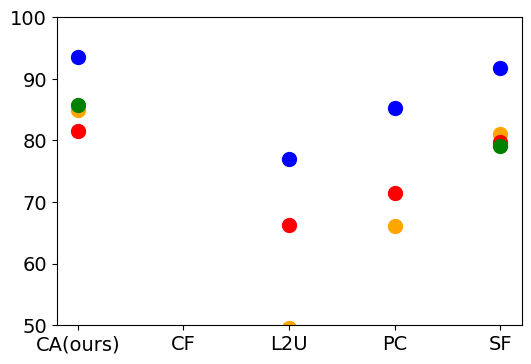

In [ ]:
# TODO: plot comparesion between ca, sfp, pc, l2f

recon_df = df[(df['config'].str.contains('reward'))]

display(recon_df)

agent_config2label = {
    ('gc_rssm', 'pc-reward'): 'PC',
    ('gc_rssm', 'cf-reward'): 'CF',
    ('gc_rssm', 'sfp-reward'): 'SF',
    ('gc_rssm', 'l2f-reward'): 'L2U',
    ('gc_rssm', 'ca-reward'): 'CA(ours)'
}


custom_order = list(agent_config2label.keys())

print(custom_order)

recon_df['agent_config'] = list(zip(recon_df['agent'], recon_df['config']))

# Map the tuple to the label
recon_df['label'] = recon_df['agent_config'].map(agent_config2label)

# Map each ('agent', 'config') pair to its position in the custom order
recon_df['sort_key'] = recon_df[['agent', 'config']].apply(tuple, axis=1).map({k: i for i, k in enumerate(custom_order)})

# Sort by the custom key
recon_df = recon_df.sort_values('sort_key').drop(columns=['sort_key'])

recon_df = recon_df.groupby('label').agg({
    'nc': 'mean',
    'IoU': 'mean',
    'ni': 'mean',
    'episodes': 'sum',
    'success_eps': 'sum'
}).reset_index()



## get the f1 score for each config using NC and IoU
recon_df['f1'] = 2*recon_df['nc']*recon_df['IoU']/(recon_df['nc'] + recon_df['IoU'])
recon_df['f1'] = recon_df['f1']*100
recon_df['sr'] = recon_df['success_eps']/recon_df['episodes'] * 100
# s
display(recon_df)

y_min = 50
y_max = 100


## show goal augmentation
goal_df = recon_df
## get rid of " Augmentation" in the config
# goal_df['config'] = goal_df['config'].str.replace(' Augmentation', '')
# plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
# plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')

plt.figure(figsize=(6, 4))  # Optional: make the figure larger

# plt.ylabel('Evaluation (%)', fontsize=18)
plt.plot(goal_df['label'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC', markersize=10)
plt.plot(goal_df['label'], goal_df['ni']*100, color='orange', marker='o', linestyle='', label='NI', markersize=10)
plt.plot(goal_df['label'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU', markersize=10)
plt.plot(goal_df['label'], goal_df['sr'], color='green', marker='o', linestyle='', label='SR', markersize=10)

plt.ylim(y_min, y_max)
# plt.legend(fontsize=14,ncol=2)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
# plt.title('F1 Score for Reward Ablation', fontsize=20)
# plt.title('F1 Score for Goal Augmentation', fontsize=20)

plt.savefig(os.path.join(analysis_pth, 'reward-ablation.png'), bbox_inches='tight')
plt.show()
